In [1]:
%pip install yfinance pandas numpy matplotlib scikit-learn

   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ----- ---------------------------------- 1.6/10.7 MB 7.6 MB/s eta 0:00:02
   ------------ --------------------------- 3.4/10.7 MB 8.7 MB/s eta 0:00:01
   --------------------- ------------------ 5.8/10.7 MB 9.9 MB/s eta 0:00:01
   ------------------------------- -------- 8.4/10.7 MB 10.5 MB/s eta 0:00:01
   ---------------------------------------  10.5/10.7 MB 10.6 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 9.3 MB/s  0:00:01
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------  2.1/2.1 MB 12.4 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 5.8 MB/s  0:00:00
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ----------------------- ---------------- 2.4/4.0 MB 10.9 MB/s eta 0:00:01
   ---------------------------------------  3.9/4.0 MB 10.9 MB/s eta 0:00:01
   ----------------------

In [2]:
print("kavi")


kavi


Please wait...


C:\jupyter\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
C:\jupyter\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)



Data downloaded successfully!
First date: 2023-10-30
Last date: 2026-10-29
Total observations: 755
Latest estimated benchmark (INR/10g): 123520.23

Training Machine Learning model...

MODEL EVALUATION
------------------------------
Test MAE:  Rs. 1,445.32 per 10g
Test RMSE: Rs. 1,809.10 per 10g

Final model trained on all available data!


C:\Users\KAVIKUMAR\AppData\Local\Temp\ipykernel_11928\4168296996.py:203: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  row["day_of_week"] = future_date.dayofweek
C:\Users\KAVIKUMAR\AppData\Local\Temp\ipykernel_11928\4168296996.py:205: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  row["day_of_year"] = future_date.dayofyear
C:\Users\KAVIKUMAR\AppData\Local\Temp\ipykernel_11928\4168296996.py:203: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  row["day_of_week"] = future_date.dayofweek
C:\Users\KAVIKUMAR\AppData\Local\Temp\ipykernel_11928\4168296996.py:205: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  row["day_of_year"] = future_date.dayofyear
C:\jupyter\.venv\Lib\sit


NEXT 30 WEEKDAY GOLD RATE PREDICTIONS


C:\jupyter\.venv\Lib\site-packages\jupyter_client\session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
C:\Users\KAVIKUMAR\AppData\Local\Temp\ipykernel_11928\4168296996.py:203: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  row["day_of_week"] = future_date.dayofweek
C:\Users\KAVIKUMAR\AppData\Local\Temp\ipykernel_11928\4168296996.py:205: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  row["day_of_year"] = future_date.dayofyear
C:\jupyter\.venv\Lib\site-packages\jupyter_client\session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware obj

,Date,Predicted Gold Rate (Rs/10g)
0,2026-10-30,124036.59
1,2026-11-02,124452.75
2,2026-11-03,125642.52
3,2026-11-04,125609.62
4,2026-11-05,125489.61
5,2026-11-06,125642.74
6,2026-11-09,126196.56
7,2026-11-10,126008.10
8,2026-11-11,125918.51
9,2026-11-12,126038.59



First predicted date: 30-10-2026
First predicted rate: Rs. 124,036.59 per 10g

Last predicted date: 10-12-2026
Last predicted rate: Rs. 126,164.13 per 10g


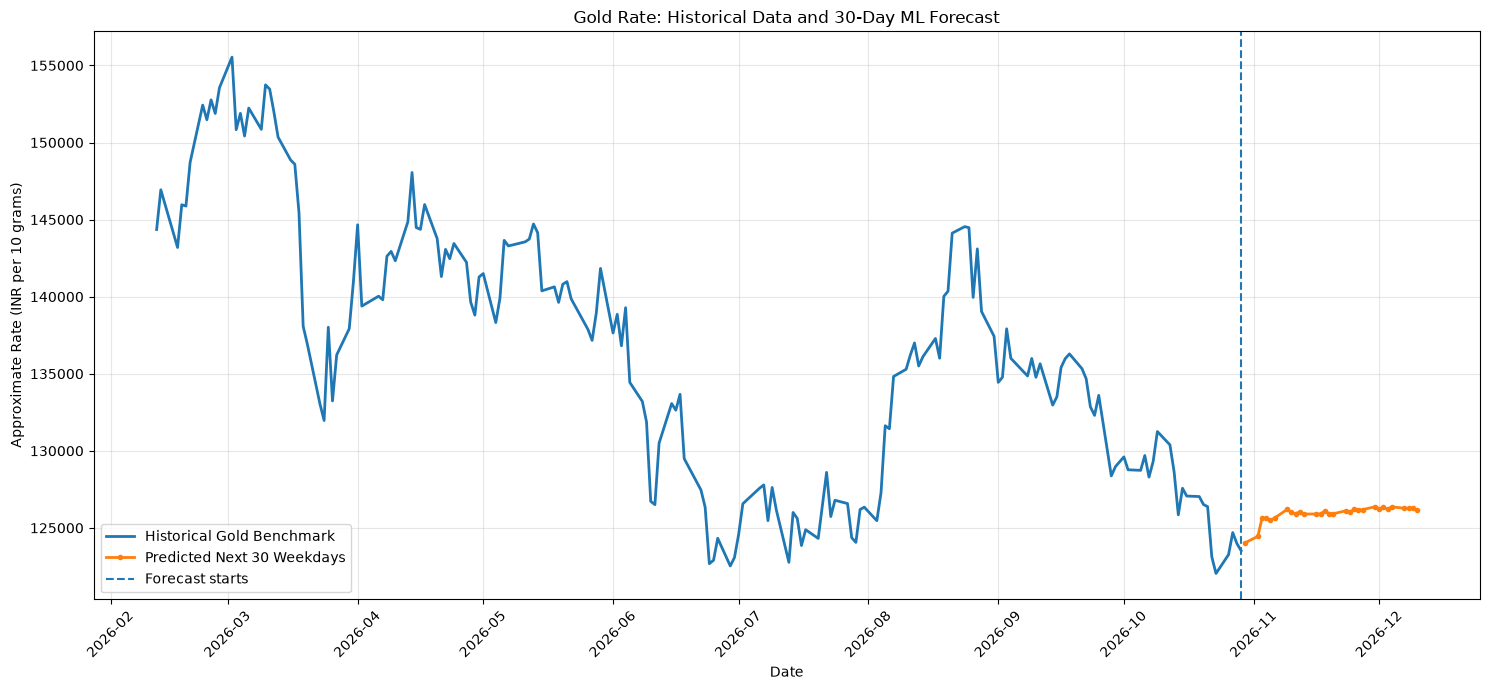


Prediction file saved:
gold_rate_predictions_next_30_days.csv


C:\jupyter\.venv\Lib\site-packages\jupyter_client\session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:

# ============================================================
# GOLD RATE PREDICTION USING MACHINE LEARNING
# Historical data: Last 3 years
# Prediction: Next 30 weekdays
# Unit: Approximate INR per 10 grams
# Model: Random Forest Regression
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. DOWNLOAD LAST 3 YEARS OF GOLD AND USD/INR DATA
# ------------------------------------------------------------

end_date = pd.Timestamp.today().normalize() + pd.Timedelta(days=1)
start_date = end_date - pd.DateOffset(years=3)

print("Downloading gold price data...")
print("Please wait...")

gold_data = yf.Ticker("GC=F").history(
    start=start_date.strftime("%Y-%m-%d"),
    end=end_date.strftime("%Y-%m-%d"),
    auto_adjust=False
)

fx_data = yf.Ticker("INR=X").history(
    start=start_date.strftime("%Y-%m-%d"),
    end=end_date.strftime("%Y-%m-%d"),
    auto_adjust=False
)

if gold_data.empty or fx_data.empty:
    raise ValueError(
        "Data download failed. Check your internet connection "
        "and try running this cell again."
    )

# Remove timezone information to align dates
gold_close = gold_data["Close"].copy()
fx_close = fx_data["Close"].copy()

gold_close.index = pd.to_datetime(gold_close.index)
fx_close.index = pd.to_datetime(fx_close.index)

if gold_close.index.tz is not None:
    gold_close.index = gold_close.index.tz_localize(None)

if fx_close.index.tz is not None:
    fx_close.index = fx_close.index.tz_localize(None)

gold_close.index = gold_close.index.normalize()
fx_close.index = fx_close.index.normalize()

# Combine gold and currency data on matching dates
data = pd.concat(
    [
        gold_close.rename("Gold_USD_per_oz"),
        fx_close.rename("USD_INR")
    ],
    axis=1
).dropna()

# Gold futures are quoted in USD per troy ounce.
# Convert to approximate INR per 10 grams.
data["Gold_INR_per_10g"] = (
    data["Gold_USD_per_oz"]
    * data["USD_INR"]
    * 10 / 31.1034768
)

prices = data["Gold_INR_per_10g"].dropna().sort_index()
prices = prices[~prices.index.duplicated(keep="last")]

if len(prices) < 200:
    raise ValueError(
        "Not enough historical data was downloaded to train the model."
    )

print("\nData downloaded successfully!")
print("First date:", prices.index.min().date())
print("Last date:", prices.index.max().date())
print("Total observations:", len(prices))
print("Latest estimated benchmark (INR/10g):",
      round(prices.iloc[-1], 2))


# ------------------------------------------------------------
# 2. CREATE FEATURES FROM HISTORICAL PRICES
# ------------------------------------------------------------

def create_features(series):
    df = pd.DataFrame({"price": series})

    # Previous prices
    for lag in [1, 2, 3, 7, 14, 30]:
        df[f"lag_{lag}"] = df["price"].shift(lag)

    # Moving averages using past data only
    for window in [7, 14, 30]:
        df[f"mean_{window}"] = (
            df["price"].shift(1).rolling(window).mean()
        )

    # Calendar features
    df["day_of_week"] = df.index.dayofweek
    df["month"] = df.index.month
    df["day_of_year"] = df.index.dayofyear

    return df.dropna()


features = create_features(prices)

X = features.drop(columns=["price"])
y = features["price"]


# ------------------------------------------------------------
# 3. TRAIN AND TEST THE MODEL CHRONOLOGICALLY
# ------------------------------------------------------------

test_size = 30
split_point = len(features) - test_size

if split_point <= 0:
    raise ValueError("Not enough data for training and testing.")

X_train = X.iloc[:split_point]
y_train = y.iloc[:split_point]

X_test = X.iloc[split_point:]
y_test = y.iloc[split_point:]

model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

print("\nTraining Machine Learning model...")
model.fit(X_train, y_train)

test_predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print("\nMODEL EVALUATION")
print("------------------------------")
print(f"Test MAE:  Rs. {mae:,.2f} per 10g")
print(f"Test RMSE: Rs. {rmse:,.2f} per 10g")

# These are one-step-ahead test predictions using actual
# previous historical prices, not a 30-day recursive test.


# ------------------------------------------------------------
# 4. RETRAIN ON ALL AVAILABLE HISTORICAL DATA
# ------------------------------------------------------------

model.fit(X, y)

print("\nFinal model trained on all available data!")


# ------------------------------------------------------------
# 5. PREDICT THE NEXT 30 WEEKDAYS
# ------------------------------------------------------------

history = prices.copy()

future_dates = pd.bdate_range(
    start=prices.index[-1] + pd.offsets.BDay(1),
    periods=30
)

future_predictions = []

for future_date in future_dates:

    row = {}

    # Previous price features
    for lag in [1, 2, 3, 7, 14, 30]:
        row[f"lag_{lag}"] = history.iloc[-lag]

    # Rolling average features
    for window in [7, 14, 30]:
        row[f"mean_{window}"] = history.iloc[-window:].mean()

    # Date features
    row["day_of_week"] = future_date.dayofweek
    row["month"] = future_date.month
    row["day_of_year"] = future_date.dayofyear

    input_data = pd.DataFrame([row], index=[future_date])
    input_data = input_data[X.columns]

    predicted_price = model.predict(input_data)[0]

    future_predictions.append(predicted_price)

    # Use prediction as the next day's lag input
    history.loc[future_date] = predicted_price


# ------------------------------------------------------------
# 6. DISPLAY DATE-WISE PREDICTIONS
# ------------------------------------------------------------

forecast = pd.Series(
    future_predictions,
    index=future_dates,
    name="Predicted_Rate_INR_per_10g"
)

forecast_table = pd.DataFrame({
    "Date": forecast.index.strftime("%Y-%m-%d"),
    "Predicted Gold Rate (Rs/10g)": forecast.round(2).values
})

print("\nNEXT 30 WEEKDAY GOLD RATE PREDICTIONS")
print("=====================================")

display(forecast_table)

print("\nFirst predicted date:",
      forecast.index[0].strftime("%d-%m-%Y"))
print("First predicted rate: Rs.",
      f"{forecast.iloc[0]:,.2f}", "per 10g")

print("\nLast predicted date:",
      forecast.index[-1].strftime("%d-%m-%Y"))
print("Last predicted rate: Rs.",
      f"{forecast.iloc[-1]:,.2f}", "per 10g")


# ------------------------------------------------------------
# 7. GRAPH: HISTORICAL VS PREDICTED GOLD RATE
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

# Show last 180 historical trading observations
recent_prices = prices.tail(180)

plt.plot(
    recent_prices.index,
    recent_prices.values,
    label="Historical Gold Benchmark",
    linewidth=2
)

plt.plot(
    forecast.index,
    forecast.values,
    label="Predicted Next 30 Weekdays",
    linewidth=2,
    marker="o",
    markersize=3
)

plt.axvline(
    prices.index[-1],
    linestyle="--",
    label="Forecast starts"
)

plt.title("Gold Rate: Historical Data and 30-Day ML Forecast")
plt.xlabel("Date")
plt.ylabel("Approximate Rate (INR per 10 grams)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. SAVE THE PREDICTIONS TO A CSV FILE
# ------------------------------------------------------------

forecast_table.to_csv(
    "gold_rate_predictions_next_30_days.csv",
    index=False
)

print("\nPrediction file saved:")
print("gold_rate_predictions_next_30_days.csv")
